# COPD - EDA, Data Cleaning, Correlation and Imbalance

Dataset: CDC BRFSS survey (`COPD_dataset.csv`). Target: `CHCCOPD3` (1 = told they have COPD, 2 = no).

Steps in this notebook:
1. Overview of the data
2. Missing values (and invalid survey codes 7 / 9)
3. Outliers / statistical values
4. Correlation - drop a column if two columns carry the same information
5. Imbalance - check it and balance the **training** set only
6. Save the clean data to `COPD_clean.csv` (used by LazyPredict, Grid Search and the final model)

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)

raw = pd.read_csv("COPD_dataset.csv")
df = raw.copy()
print(df.shape)

(457670, 8)


## 1. Overview

In [2]:
display(df.head())
df.info()
display(df.describe().T)

,CHCCOPD3,_AGE80,SEXVAR,_BMI5,SMOKE100,SMOKDAY2,EXERANY2,GENHLTH
0,2.0,78.0,2.0,2249.0,2.0,NaN,1.0,3.0
1,2.0,80.0,1.0,2583.0,1.0,3.0,1.0,1.0
2,2.0,59.0,1.0,2253.0,1.0,1.0,1.0,2.0
3,2.0,80.0,1.0,2509.0,2.0,NaN,1.0,1.0
4,2.0,47.0,1.0,1977.0,2.0,NaN,2.0,3.0


<class 'pandas.DataFrame'>
RangeIndex: 457670 entries, 0 to 457669
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   CHCCOPD3  457663 non-null  float64
 1   _AGE80    457670 non-null  float64
 2   SEXVAR    457670 non-null  float64
 3   _BMI5     414633 non-null  float64
 4   SMOKE100  428810 non-null  float64
 5   SMOKDAY2  167076 non-null  float64
 6   EXERANY2  457667 non-null  float64
 7   GENHLTH   457665 non-null  float64
dtypes: float64(8)
memory usage: 27.9 MB


,count,mean,std,min,25%,50%,75%,max
CHCCOPD3,457663.0,1.944077,0.456968,1.0,2.0,2.0,2.0,9.0
_AGE80,457670.0,55.084784,18.127835,18.0,40.0,58.0,71.0,80.0
SEXVAR,457670.0,1.524795,0.499385,1.0,1.0,2.0,2.0,2.0
_BMI5,414633.0,2855.680093,658.616131,1200.0,2414.0,2744.0,3175.0,9984.0
SMOKE100,428810.0,1.643007,0.667560,1.0,1.0,2.0,2.0,9.0
SMOKDAY2,167076.0,2.531375,0.846432,1.0,2.0,3.0,3.0,9.0
EXERANY2,457667.0,1.251427,0.547624,1.0,1.0,1.0,1.0,9.0
GENHLTH,457665.0,2.659362,1.081163,1.0,2.0,3.0,3.0,9.0


## 2. Missing values

Two kinds of "missing" exist in a BRFSS survey:
* real blanks (`NaN`)
* codes **7 = Don't know** and **9 = Refused**, which are NOT real answers, so we treat them as missing too.

In [3]:
cols = ["CHCCOPD3", "SMOKE100", "SMOKDAY2", "EXERANY2", "GENHLTH"]
summary = pd.DataFrame({
    "NaN": df[cols].isna().sum(),
    "7 (don't know)": (df[cols] == 7).sum(),
    "9 (refused)": (df[cols] == 9).sum(),
})
display(summary)

print("Share of NaN per column (%):")
display((df.isna().mean() * 100).round(2))

,NaN,7 (don't know),9 (refused)
CHCCOPD3,7,1921,246
SMOKE100,28860,2062,550
SMOKDAY2,290594,194,190
EXERANY2,3,860,452
GENHLTH,5,915,390


Share of NaN per column (%):


CHCCOPD3     0.00
_AGE80       0.00
SEXVAR       0.00
_BMI5        9.40
SMOKE100     6.31
SMOKDAY2    63.49
EXERANY2     0.00
GENHLTH      0.00
dtype: float64

In [4]:
# 2.1 Target: keep only clear answers (1 = COPD, 2 = no COPD)
before = len(df)
df = df[df["CHCCOPD3"].isin([1.0, 2.0])].copy()
df["COPD"] = (df["CHCCOPD3"] == 1.0).astype(int)
print(f"Dropped {before - len(df)} rows with unknown/refused/missing target -> {len(df)} rows left")

# 2.2 7 / 9 codes -> NaN
for c in ["SMOKE100", "SMOKDAY2", "EXERANY2", "GENHLTH"]:
    df[c] = df[c].replace({7.0: np.nan, 9.0: np.nan})

# 2.3 _BMI5 is stored as BMI x 100
df["BMI"] = df["_BMI5"] / 100

# 2.4 SMOKDAY2 is only asked of people who smoked 100+ cigarettes (SMOKE100 = 1).
#     For never-smokers (SMOKE100 = 2) the blank is "not applicable", not "unknown" -> code it as 0.
print("SMOKDAY2 blank among never-smokers:", df.loc[df.SMOKE100 == 2, "SMOKDAY2"].isna().mean().round(3))
df.loc[df["SMOKE100"] == 2.0, "SMOKDAY2"] = 0.0
print("SMOKDAY2 values: 0 = never smoked, 1 = every day, 2 = some days, 3 = former smoker")

Dropped 2174 rows with unknown/refused/missing target -> 455496 rows left
SMOKDAY2 blank among never-smokers: 1.0
SMOKDAY2 values: 0 = never smoked, 1 = every day, 2 = some days, 3 = former smoker


## 3. Outliers / statistical values

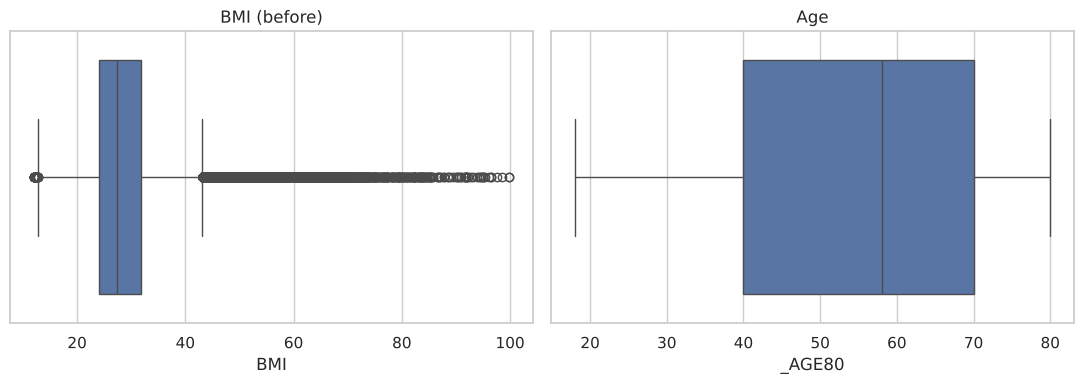

BMI IQR fences: [12.7, 43.2]  -> 12971 values outside
BMI < 14: 219 | BMI > 60: 867 | max: 99.84
Age range: 18.0 - 80.0 (no outliers; 80 means 80+)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df["BMI"], ax=ax[0]); ax[0].set_title("BMI (before)")
sns.boxplot(x=df["_AGE80"], ax=ax[1]); ax[1].set_title("Age")
plt.tight_layout(); plt.show()

q1, q3 = df["BMI"].quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"BMI IQR fences: [{lo:.1f}, {hi:.1f}]  -> {((df.BMI < lo) | (df.BMI > hi)).sum()} values outside")
print("BMI < 14:", (df.BMI < 14).sum(), "| BMI > 60:", (df.BMI > 60).sum(), "| max:", df.BMI.max())
print("Age range:", df._AGE80.min(), "-", df._AGE80.max(), "(no outliers; 80 means 80+)")

The 1.5 x IQR rule would cut BMI at about 43, but BMI 43-60 is real severe obesity and carries
information. So we only fix **physiologically implausible** values: BMI is capped (winsorized) to **[14, 60]**.
Age has no outliers.

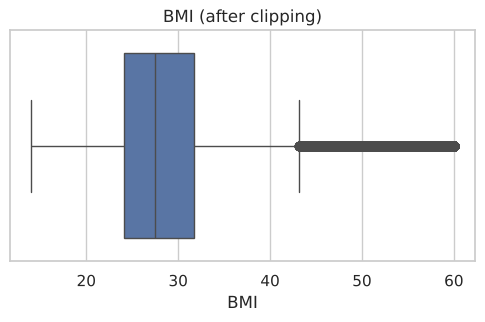

,count,mean,std,min,25%,50%,75%,max
_AGE80,455496.0,55.069669,18.125878,18.0,40.00,58.00,70.00,80.0
SEXVAR,455496.0,1.525098,0.499370,1.0,1.00,2.00,2.00,2.0
BMI,412881.0,28.536793,6.469977,14.0,24.14,27.44,31.75,60.0
SMOKE100,424317.0,1.608052,0.488186,1.0,1.00,2.00,2.00,2.0
SMOKDAY2,423775.0,0.985733,1.328534,0.0,0.00,0.00,3.00,3.0
EXERANY2,454273.0,1.232338,0.422324,1.0,1.00,1.00,1.00,2.0
GENHLTH,454269.0,2.642337,1.047684,1.0,2.00,3.00,3.00,5.0
COPD,455496.0,0.081057,0.272922,0.0,0.00,0.00,0.00,1.0


In [6]:
BMI_MIN, BMI_MAX = 14.0, 60.0
df["BMI"] = df["BMI"].clip(BMI_MIN, BMI_MAX)

fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(x=df["BMI"], ax=ax); ax.set_title("BMI (after clipping)")
plt.show()
FEATURES_ALL = ["_AGE80", "SEXVAR", "BMI", "SMOKE100", "SMOKDAY2", "EXERANY2", "GENHLTH"]
display(df[FEATURES_ALL + ["COPD"]].describe().T)

## 4. Correlation

If two features are highly correlated (|r| > 0.8) they carry the same information, so we drop one.

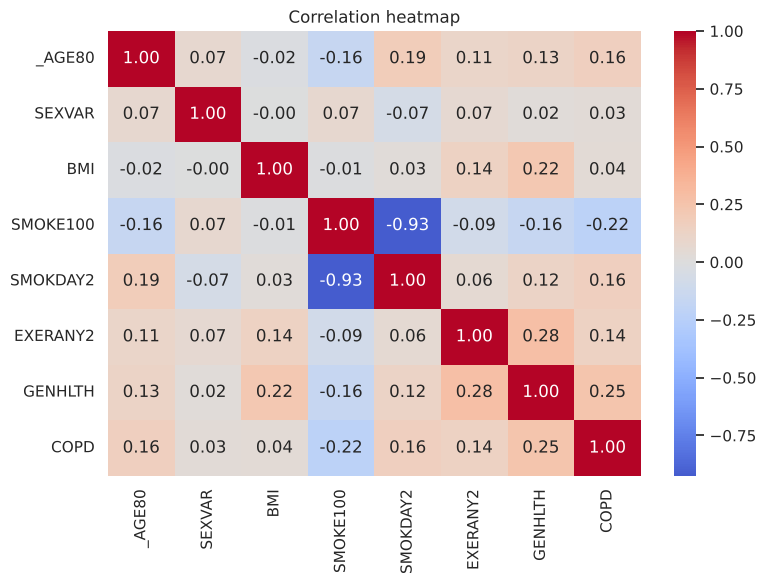

Highly correlated pairs (|r| > 0.8): [('SMOKE100', 'SMOKDAY2', np.float64(-0.9256624859939313))]

Correlation with the target:


SMOKE100   -0.219219
SEXVAR      0.032505
BMI         0.044142
EXERANY2    0.141129
_AGE80      0.157863
SMOKDAY2    0.162006
GENHLTH     0.245352
Name: COPD, dtype: float64

In [7]:
corr = df[FEATURES_ALL + ["COPD"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES_ALL) for b in FEATURES_ALL[i + 1:]
         if abs(corr.loc[a, b]) > 0.8]
print("Highly correlated pairs (|r| > 0.8):", pairs)
print("\nCorrelation with the target:")
display(corr["COPD"].drop("COPD").sort_values())

`SMOKE100` and `SMOKDAY2` have r = **-0.93**. They are the same information:
`SMOKDAY2 = 0` already means "never smoked" (`SMOKE100 = 2`), and 1/2/3 means smoked 100+ cigarettes.
`SMOKDAY2` is more detailed (every day / some days / former), so we **drop `SMOKE100`** and keep `SMOKDAY2`.

In [8]:
DROP = ["SMOKE100"]
FEATURES = [c for c in FEATURES_ALL if c not in DROP]
print("Dropped:", DROP, "\nFeatures used:", FEATURES)

Dropped: ['SMOKE100'] 
Features used: ['_AGE80', 'SEXVAR', 'BMI', 'SMOKDAY2', 'EXERANY2', 'GENHLTH']


## 5. Split, impute, then check imbalance

We split **before** imputing/balancing so the test set stays untouched (no data leakage).
Imputation values are learned from the training set only: **median** for numeric columns (age, BMI),
**most frequent value** for the coded columns.

In [9]:
data = df[FEATURES + ["COPD"]].reset_index(drop=True)
X, y = data[FEATURES], data["COPD"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "test:", X_test.shape)

NUMERIC = ["_AGE80", "BMI"]
fill = {c: (X_train[c].median() if c in NUMERIC else X_train[c].mode().iloc[0]) for c in FEATURES}
print("Fill values (from train only):", fill)
print("Missing before:", X.isna().sum()[X.isna().sum() > 0].to_dict())

data_clean = data.copy()
data_clean[FEATURES] = data_clean[FEATURES].fillna(fill)
print("Missing after :", int(data_clean.isna().sum().sum()))

X_train, X_test = data_clean.loc[X_train.index, FEATURES], data_clean.loc[X_test.index, FEATURES]
y_train, y_test = data_clean.loc[y_train.index, "COPD"], data_clean.loc[y_test.index, "COPD"]

train: (364396, 6) test: (91100, 6)


Fill values (from train only): {'_AGE80': np.float64(58.0), 'SEXVAR': np.float64(2.0), 'BMI': np.float64(27.44), 'SMOKDAY2': np.float64(0.0), 'EXERANY2': np.float64(1.0), 'GENHLTH': np.float64(3.0)}
Missing before: {'BMI': 42615, 'SMOKDAY2': 31721, 'EXERANY2': 1223, 'GENHLTH': 1227}
Missing after : 0


COPD
0    334859
1     29537
COPD share: 8.1%  -> imbalance ratio 11.3 : 1


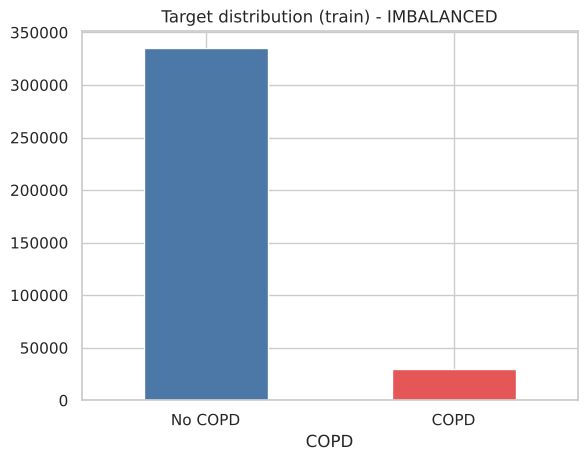

In [10]:
counts = y_train.value_counts().sort_index()
print(counts.to_string())
print(f"COPD share: {y_train.mean():.1%}  -> imbalance ratio {counts[0] / counts[1]:.1f} : 1")
ax = counts.rename({0: "No COPD", 1: "COPD"}).plot(kind="bar", color=["#4C78A8", "#E45756"], rot=0)
ax.set_title("Target distribution (train) - IMBALANCED"); plt.show()

### Balancing - which method?

Only 8% of people have COPD. We try 4 options **on the training set only** and evaluate on the untouched test set.
* **None** - as is
* **class_weight** - the model penalises mistakes on COPD more
* **Random under-sampling** - drop random non-COPD rows
* **Random over-sampling** - duplicate COPD rows (SMOTE is not used because it would invent values such as
  `GENHLTH = 2.4`, which are meaningless for coded survey answers)

In [11]:
P = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=100,
         random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)

def run(name, Xtr, ytr, **kw):
    m = lgb.LGBMClassifier(**P, **kw).fit(Xtr, ytr)
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {"method": name, "train rows": len(Xtr), "COPD share in train": round(float(np.mean(ytr)), 3),
            "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
            "recall@0.5": recall_score(y_test, pred), "precision@0.5": precision_score(y_test, pred),
            "balanced acc@0.5": balanced_accuracy_score(y_test, pred)}

Xu, yu = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
Xo, yo = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
res = pd.DataFrame([
    run("None", X_train, y_train),
    run("class_weight=balanced", X_train, y_train, class_weight="balanced"),
    run("Under-sampling", Xu, yu),
    run("Over-sampling", Xo, yo),
]).set_index("method")
display(res.round(4))

,train rows,COPD share in train,ROC-AUC,PR-AUC,recall@0.5,precision@0.5,balanced acc@0.5
method,,,,,,,
None,364396,0.081,0.8253,0.3352,0.0886,0.5571,0.5412
class_weight=balanced,364396,0.081,0.8255,0.3353,0.7580,0.2076,0.7514
Under-sampling,59074,0.500,0.8250,0.3336,0.7602,0.2078,0.7523
Over-sampling,669718,0.500,0.8252,0.3348,0.7568,0.2077,0.7510


**Reading the table:** balancing does not change the ranking quality (ROC-AUC / PR-AUC are almost the same),
but it moves the model from "almost never says COPD" (recall ~9%) to "catches about 3 out of 4 COPD cases"
at the default 0.5 cut-off, at the price of lower precision. That is what we want for a screening tool.
Balancing also makes the raw probabilities too high, so the final model **re-calibrates** them on an
untouched (natural 8%) split. We use **under-sampling** for the model comparison and the grid search
(fast and no duplicated rows).

## 6. Save the clean data

In [12]:
data_clean.to_csv("COPD_clean.csv", index=False)
meta = {
    "features": FEATURES, "dropped_columns": DROP, "target": "COPD",
    "bmi_clip": [BMI_MIN, BMI_MAX], "fill_values": {k: float(v) for k, v in fill.items()},
    "numeric": NUMERIC, "random_state": RANDOM_STATE, "test_size": 0.20,
    "balancing": "RandomUnderSampler on the training split only",
}
(ARTIFACTS / "copd_cleaning.json").write_text(json.dumps(meta, indent=2))
print(data_clean.shape, "saved to COPD_clean.csv; settings saved to artifacts/copd_cleaning.json")
data_clean.head()

(455496, 7) saved to COPD_clean.csv; settings saved to artifacts/copd_cleaning.json


,_AGE80,SEXVAR,BMI,SMOKDAY2,EXERANY2,GENHLTH,COPD
0,78.0,2.0,22.49,0.0,1.0,3.0,0
1,80.0,1.0,25.83,3.0,1.0,1.0,0
2,59.0,1.0,22.53,1.0,1.0,2.0,0
3,80.0,1.0,25.09,0.0,1.0,1.0,0
4,47.0,1.0,19.77,0.0,2.0,3.0,0
